## Assignment -8-

**Time Series Forecasting Systems: Reproducible Analysis, SARIMA Modeling, and Backtesting**

## Context and Scenario
You are supporting a climate analytics team that monitors atmospheric CO₂ dynamics and requires a forecasting workflow suitable for operational use. The objective is not only to build a statistically reasonable forecast, but also to design a pipeline that is reproducible, validated, and monitorable in deployment. Your notebook should reflect the concerns of a machine learning systems engineer: data quality, leakage prevention, stability under temporal drift, evaluation under realistic forecasting conditions, and operational rollback readiness.

## Dataset
Use the **Mauna Loa Atmospheric CO₂** time series available through `statsmodels.datasets.co2.load_pandas()`. The series contains atmospheric CO₂ measurements from Mauna Loa, Hawaii, and is appropriate for studying trend, seasonality, non-stationarity, preprocessing, and forecasting. You are expected to convert the raw series into an analysis-ready monthly time series, validate schema and ranges, and document any imputation or resampling decisions. Students must cite the dataset page in the notebook.

## Machine Learning Tasks
Your notebook must implement a concise but complete time-series modeling workflow. At minimum, this includes: loading and validating the dataset; exploratory analysis; rolling mean visualization; additive seasonal decomposition; stationarity testing with the Augmented Dickey-Fuller test; first-order differencing; calendar-based feature engineering; scaling of engineered features; a transparent EWMA baseline; a SARIMA forecasting model; rolling-origin backtesting with MAE and RMSE; and residual diagnostics using plots and autocorrelation analysis. You must also include short written reflections on monitoring metrics, forecast drift, reproducibility artifacts, and limitations of the current pipeline.

## Deliverables
Submit:
1. An executed Jupyter notebook.
2. Short written answers embedded in Markdown cells.

Your work will be assessed on technical correctness, clarity of interpretation, and evidence of ML systems thinking. 
Random train/test splitting is not acceptable. All preprocessing and evaluation decisions must respect temporal order.



## Grading Rubric (100 points)

| Criterion | Points |
|---|---:|
| Code correctness and notebook execution | 30 |
| Data validation and preprocessing quality | 15 |
| Time series analysis quality (EDA, decomposition, stationarity, forecasting) | 20 |
| Interpretation of results and written responses | 15 |
| Systems thinking (reproducibility, leakage prevention, monitoring, drift, compute cost) | 15 |
| Clarity, organization, and professionalism | 5 |


__________________________________________________________________________________________________________________________________________________________________________________

# Assignment 8
### Time Series Forecasting Systems: Reproducible Analysis, SARIMA Modeling, and Backtesting

## Context and Scenario

The goal is to analyze and forecast atmospheric CO2 levels. The workflow focuses on time aware validation, leakage prevention, reproducibility, and monitoring.

## Dataset

The data comes from the Mauna Loa Atmospheric CO2 dataset available through statsmodels. The original observations are converted into a monthly time series for analysis.

In [1]:
# Reproducibility and imports

import sys
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels
from statsmodels.datasets import co2
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python:", sys.version)
print("Platform:", platform.platform())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("statsmodels:", statsmodels.__version__)
print("Random seed:", RANDOM_STATE)

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Platform: Windows-11-10.0.26200-SP0
pandas: 2.3.3
NumPy: 2.5.3
statsmodels: 0.14.5
Random seed: 42


## Data Loading

The CO2 data is loaded using `statsmodels.datasets.co2.load_pandas()`.

In [2]:
co2_data = co2.load_pandas()

raw = co2_data.data.copy()

print("Raw shape:", raw.shape)
display(raw.head())
display(raw.tail())

Raw shape: (2284, 1)


,co2
1958-03-29,316.1
1958-04-05,317.3
1958-04-12,317.6
1958-04-19,317.5
1958-04-26,316.4


,co2
2001-12-01,370.3
2001-12-08,370.8
2001-12-15,371.2
2001-12-22,371.3
2001-12-29,371.5


## Data Validation

I checked the index, missing values, duplicates, and CO2 value range before resampling.

In [3]:
print("Columns:")
print(raw.columns.tolist())

print("\nData types:")
print(raw.dtypes)

print("\nMissing values:")
print(raw.isna().sum())

print("\nDuplicate index values:", raw.index.duplicated().sum())

print("\nSummary:")
display(raw.describe())

Columns:
['co2']

Data types:
co2    float64
dtype: object

Missing values:
co2    59
dtype: int64

Duplicate index values: 0

Summary:


,co2
count,2225.000000
mean,340.142247
std,17.003885
min,313.000000
25%,324.800000
50%,338.300000
75%,354.800000
max,373.900000


In [4]:
# Basic validation

assert len(raw.columns) == 1
assert raw.index.is_monotonic_increasing
assert raw.index.duplicated().sum() == 0

print("Minimum CO₂:", raw["co2"].min())
print("Maximum CO₂:", raw["co2"].max())

assert raw["co2"].dropna().min() > 0

print("\nBasic validation passed.")

Minimum CO₂: 313.0
Maximum CO₂: 373.9

Basic validation passed.


## Monthly Time Series

The original data contains missing observations, so I resample it to monthly averages. Missing monthly values are filled using time-based interpolation.

In [5]:
monthly = raw["co2"].resample("MS").mean()

print("Monthly observations before interpolation:", len(monthly))
print("Missing monthly values:", monthly.isna().sum())

Monthly observations before interpolation: 526
Missing monthly values: 5


In [6]:
monthly = monthly.interpolate(method="time")

print("Missing values after interpolation:", monthly.isna().sum())

print("\nMonthly date range:")
print(monthly.index.min(), "to", monthly.index.max())

display(monthly.head())

Missing values after interpolation: 0

Monthly date range:
1958-03-01 00:00:00 to 2001-12-01 00:00:00


1958-03-01    316.100000
1958-04-01    317.200000
1958-05-01    317.433333
1958-06-01    316.514344
1958-07-01    315.625000
Freq: MS, Name: co2, dtype: float64

### Resampling

Monthly averages reduce the noise in the original measurements while keeping the long-term trend and yearly seasonality. Interpolation was only used for missing monthly observations and was performed before modeling.

## Exploratory Analysis

The time series shows a clear upward trend and repeating seasonal pattern.

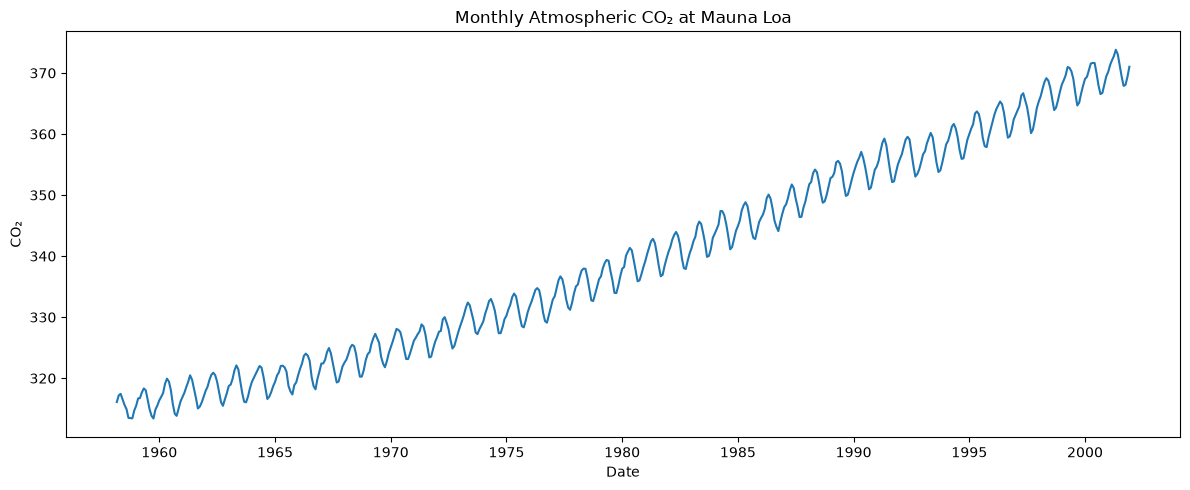

In [7]:
plt.figure(figsize=(12, 5))

plt.plot(monthly.index, monthly.values)

plt.xlabel("Date")
plt.ylabel("CO₂")
plt.title("Monthly Atmospheric CO₂ at Mauna Loa")

plt.tight_layout()
plt.show()

## Rolling Mean

A rolling mean makes the long-term trend easier to see while reducing short-term variation.

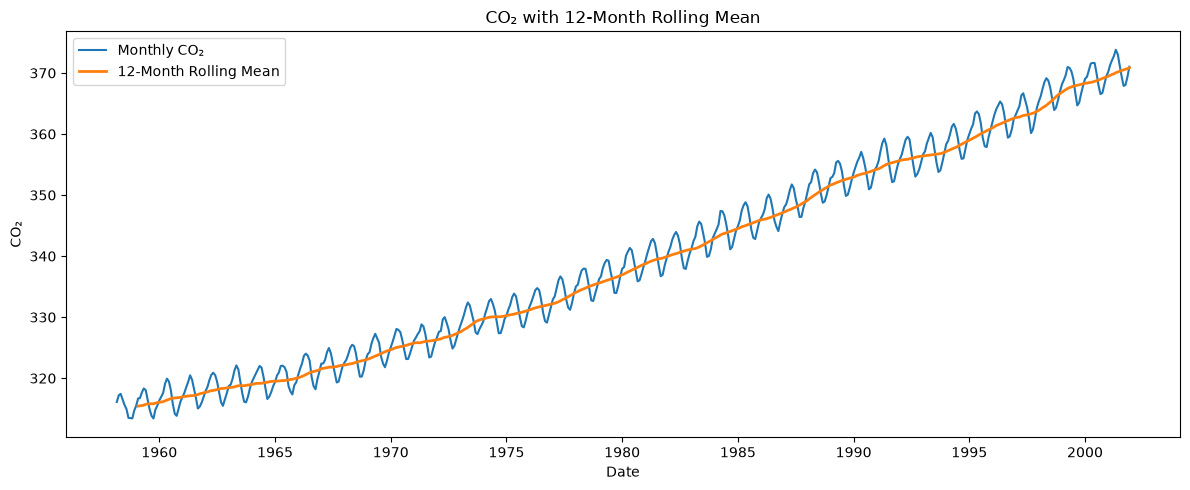

In [8]:
rolling_mean = monthly.rolling(window=12).mean()

plt.figure(figsize=(12, 5))

plt.plot(monthly.index, monthly, label="Monthly CO₂")
plt.plot(
    rolling_mean.index,
    rolling_mean,
    label="12-Month Rolling Mean",
    linewidth=2
)

plt.xlabel("Date")
plt.ylabel("CO₂")
plt.title("CO₂ with 12-Month Rolling Mean")
plt.legend()

plt.tight_layout()
plt.show()

### Rolling Mean Interpretation

The rolling mean shows the long-term increase in CO2 while smoothing the yearly fluctuations.

## Seasonal Decomposition

I use additive decomposition to separate the series into trend, seasonal, and residual components.

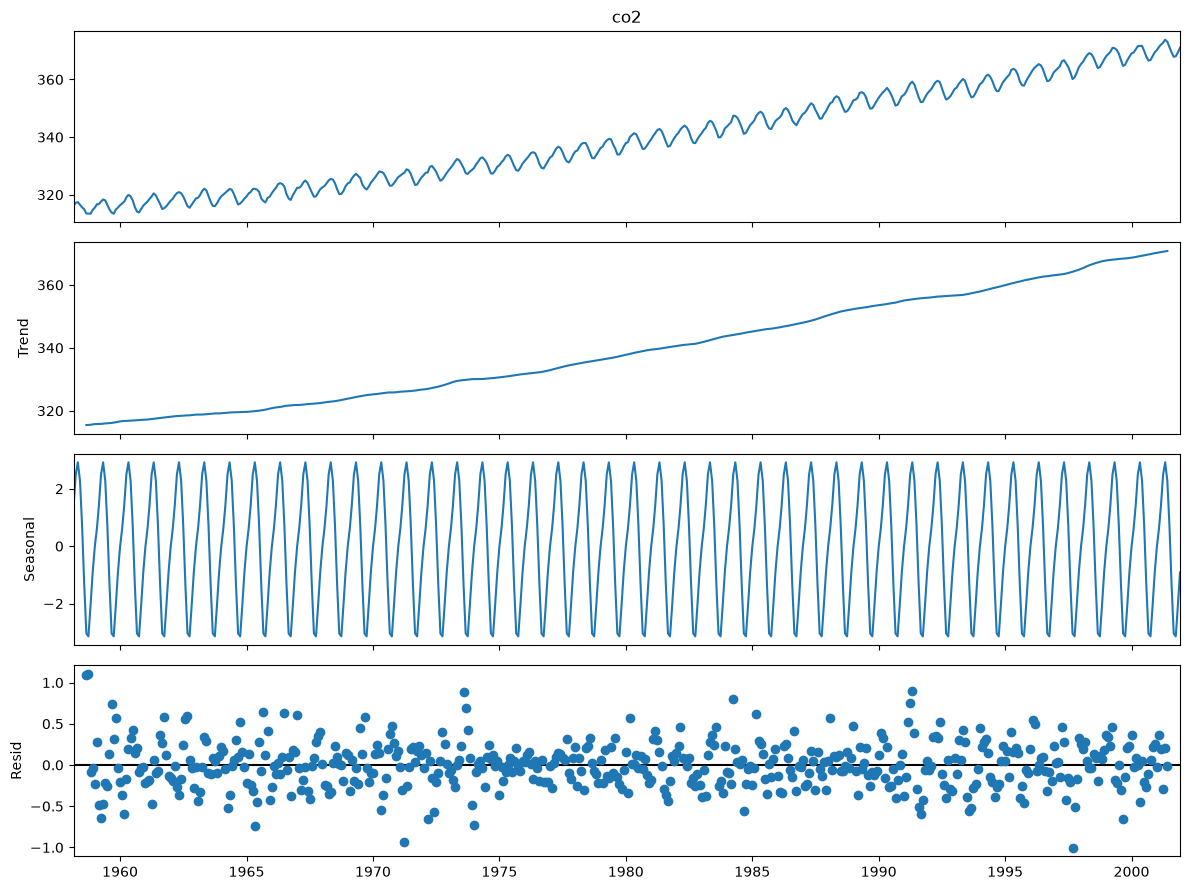

In [9]:
decomposition = seasonal_decompose(
    monthly,
    model="additive",
    period=12
)

fig = decomposition.plot()
fig.set_size_inches(12, 9)

plt.tight_layout()
plt.show()

### Decomposition Interpretation

The decomposition shows a strong trend and a repeating yearly seasonal pattern. The residual component contains variation that is not explained by the trend and seasonality.

## Time-Based Train & Test Split

I use the first 80% of the observations for training and the final 20% for testing. No random shuffling is used because future observations cant be used to predict the past.

In [10]:
split_index = int(len(monthly) * 0.80)

train = monthly.iloc[:split_index].copy()
test = monthly.iloc[split_index:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 420
Testing observations: 106

Training period:
1958-03-01 00:00:00 to 1993-02-01 00:00:00

Testing period:
1993-03-01 00:00:00 to 2001-12-01 00:00:00


## Stationarity Test

The Augmented Dickey-Fuller test checks whether the series is stationary. The original CO2 series is expected to be non-stationary because of its trend.

In [11]:
adf_result = adfuller(train.dropna())

print("ADF statistic:", adf_result[0])
print("p-value:", adf_result[1])

print("\nCritical values:")
for key, value in adf_result[4].items():
    print(f"{key}: {value}")

ADF statistic: 1.7838386804903297
p-value: 0.9983164192633638

Critical values:
1%: -3.446599953548936
5%: -2.86870295908671
10%: -2.570585643956714


### ADF Interpretation

A large p-value suggests that the original series is not stationary. The visible trend also supports the need for differencing before modeling.

## First Order Differencing

First order differencing removes much of the long-term trend from the series.

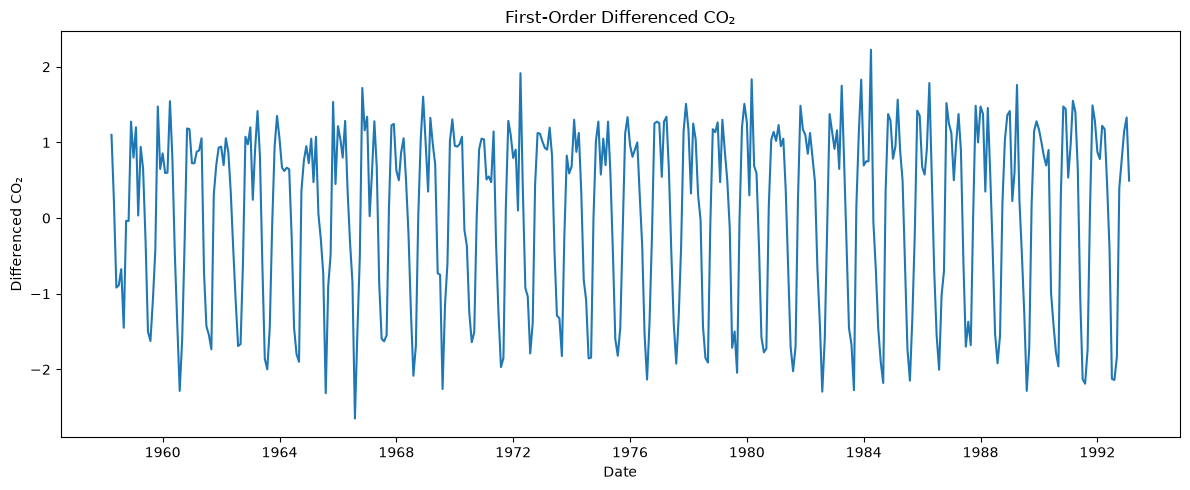

In [12]:
train_diff = train.diff().dropna()

plt.figure(figsize=(12, 5))

plt.plot(train_diff.index, train_diff)

plt.xlabel("Date")
plt.ylabel("Differenced CO₂")
plt.title("First-Order Differenced CO₂")

plt.tight_layout()
plt.show()

In [13]:
adf_diff = adfuller(train_diff)

print("ADF statistic after differencing:", adf_diff[0])
print("p-value after differencing:", adf_diff[1])

print("\nCritical values:")
for key, value in adf_diff[4].items():
    print(f"{key}: {value}")

ADF statistic after differencing: -3.984514957112495
p-value after differencing: 0.0014938016625174557

Critical values:
1%: -3.44664043608676
5%: -2.868720756230461
10%: -2.5705951311145965


### Differencing Interpretation

After differencing, the series is much closer to stationary. This supports using a differencing term in the SARIMA model.

## Calendar Features

I create simple calendar features for month seasonality and the long-term time trend. These features are also scaled for consistent preprocessing.

In [14]:
feature_data = pd.DataFrame(index=monthly.index)

feature_data["year"] = feature_data.index.year
feature_data["month"] = feature_data.index.month

feature_data["month_sin"] = np.sin(
    2 * np.pi * feature_data["month"] / 12
)

feature_data["month_cos"] = np.cos(
    2 * np.pi * feature_data["month"] / 12
)

feature_data["time_index"] = np.arange(len(feature_data))

display(feature_data.head())

,year,month,month_sin,month_cos,time_index
1958-03-01,1958,3,1.000000e+00,6.123234e-17,0
1958-04-01,1958,4,8.660254e-01,-5.000000e-01,1
1958-05-01,1958,5,5.000000e-01,-8.660254e-01,2
1958-06-01,1958,6,1.224647e-16,-1.000000e+00,3
1958-07-01,1958,7,-5.000000e-01,-8.660254e-01,4


## Feature Scaling

The scaler is fit only on the training period. The test data is transformed using the same scaler so future information does not affect preprocessing.

In [15]:
feature_train = feature_data.loc[train.index]
feature_test = feature_data.loc[test.index]

feature_columns = [
    "year",
    "month",
    "month_sin",
    "month_cos",
    "time_index"
]

scaler = StandardScaler()

scaled_train = scaler.fit_transform(
    feature_train[feature_columns]
)

scaled_test = scaler.transform(
    feature_test[feature_columns]
)

scaled_train = pd.DataFrame(
    scaled_train,
    index=feature_train.index,
    columns=feature_columns
)

scaled_test = pd.DataFrame(
    scaled_test,
    index=feature_test.index,
    columns=feature_columns
)

display(scaled_train.head())

,year,month,month_sin,month_cos,time_index
1958-03-01,-1.698597,-1.013890,1.414214e+00,1.508946e-16,-1.727932
1958-04-01,-1.698597,-0.724207,1.224745e+00,-7.071068e-01,-1.719684
1958-05-01,-1.698597,-0.434524,7.071068e-01,-1.224745e+00,-1.711436
1958-06-01,-1.698597,-0.144841,1.971164e-16,-1.414214e+00,-1.703188
1958-07-01,-1.698597,0.144841,-7.071068e-01,-1.224745e+00,-1.694940


## EWMA Baseline

The EWMA baseline gives more weight to recent observations. This provides a simple benchmark for the SARIMA model.

In [16]:
def ewma_forecast(train_series, horizon, span=12):
    model = train_series.ewm(
        span=span,
        adjust=False
    ).mean()

    last_value = model.iloc[-1]

    return np.repeat(last_value, horizon)


ewma_pred = ewma_forecast(
    train,
    len(test),
    span=12
)

ewma_mae = mean_absolute_error(
    test,
    ewma_pred
)

ewma_rmse = np.sqrt(
    mean_squared_error(test, ewma_pred)
)

print("EWMA MAE:", round(ewma_mae, 3))
print("EWMA RMSE:", round(ewma_rmse, 3))

EWMA MAE: 8.583
EWMA RMSE: 9.789


## SARIMA Forecast

The CO2 data has yearly seasonality, so I use a seasonal period of 12 months. The SARIMA model uses first-order regular and seasonal differencing.

In [17]:
sarima_order = (1, 1, 1)
seasonal_order = (1, 1, 1, 12)

sarima_model = SARIMAX(
    train,
    order=sarima_order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(
    disp=False
)

print(sarima_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                                co2   No. Observations:                  420
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                 -85.986
Date:                            Fri, 16 Oct 2026   AIC                            181.972
Time:                                    14:47:55   BIC                            201.841
Sample:                                03-01-1958   HQIC                           189.846
                                     - 02-01-1993                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2522      0.118      2.129      0.033       0.020       0.484
ma.L1         -0.5980      0.102   

In [18]:
sarima_forecast = sarima_fit.forecast(
    steps=len(test)
)

sarima_forecast.index = test.index

sarima_mae = mean_absolute_error(
    test,
    sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(
        test,
        sarima_forecast
    )
)

print("SARIMA MAE:", round(sarima_mae, 3))
print("SARIMA RMSE:", round(sarima_rmse, 3))

SARIMA MAE: 1.852
SARIMA RMSE: 2.184


## Forecast Comparison

The plot compares the actual test values with the EWMA and SARIMA forecasts.

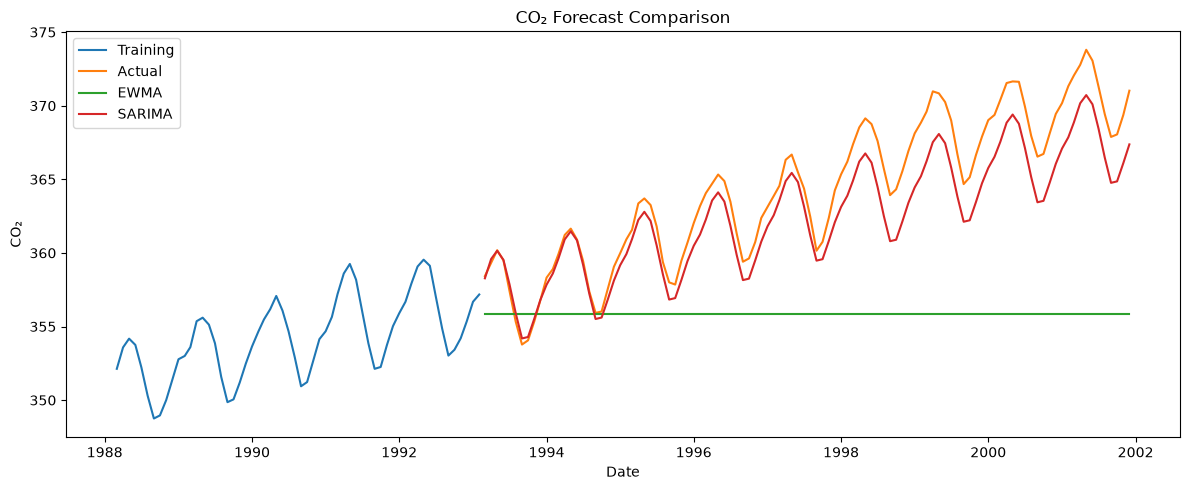

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(
    train.index[-60:],
    train.iloc[-60:],
    label="Training"
)

plt.plot(
    test.index,
    test,
    label="Actual"
)

plt.plot(
    test.index,
    ewma_pred,
    label="EWMA"
)

plt.plot(
    test.index,
    sarima_forecast,
    label="SARIMA"
)

plt.xlabel("Date")
plt.ylabel("CO₂")
plt.title("CO₂ Forecast Comparison")
plt.legend()

plt.tight_layout()
plt.show()

## Model Comparison

Lower MAE and RMSE indicate better forecasting performance.

In [20]:
model_results = pd.DataFrame({
    "Model": [
        "EWMA",
        "SARIMA"
    ],
    "MAE": [
        ewma_mae,
        sarima_mae
    ],
    "RMSE": [
        ewma_rmse,
        sarima_rmse
    ]
})

model_results

,Model,MAE,RMSE
0,EWMA,8.582523,9.788935
1,SARIMA,1.852472,2.183999


## Rolling-Origin Backtesting

A single train/test split can give a misleading result. Rolling-origin backtesting repeatedly trains on past observations and evaluates the next 12 months.

In [21]:
def evaluate_forecast(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    }

In [23]:
initial_train_size = 20 * 12
horizon = 12
step = 12

backtest_rows = []

for end in range(
    initial_train_size,
    len(monthly) - horizon + 1,
    step
):
    train_bt = monthly.iloc[:end]
    test_bt = monthly.iloc[end:end + horizon]

    # EWMA
    ewma_bt = ewma_forecast(
        train_bt,
        horizon,
        span=12
    )

    ewma_metrics = evaluate_forecast(
        test_bt,
        ewma_bt
    )

    backtest_rows.append({
        "origin": test_bt.index[0],
        "model": "EWMA",
        "MAE": ewma_metrics["MAE"],
        "RMSE": ewma_metrics["RMSE"]
    })

    # SARIMA
    model_bt = SARIMAX(
        train_bt,
        order=sarima_order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fit_bt = model_bt.fit(disp=False)

    pred_bt = fit_bt.forecast(
        steps=horizon
    )

    pred_bt.index = test_bt.index

    sarima_metrics = evaluate_forecast(
        test_bt,
        pred_bt
    )

    backtest_rows.append({
        "origin": test_bt.index[0],
        "model": "SARIMA",
        "MAE": sarima_metrics["MAE"],
        "RMSE": sarima_metrics["RMSE"]
    })

backtest_results = pd.DataFrame(backtest_rows)

display(backtest_results)

,origin,model,MAE,RMSE
0,1978-03-01,EWMA,2.311239,2.678701
1,1978-03-01,SARIMA,0.357121,0.393821
2,1979-03-01,EWMA,2.304148,2.638600
3,1979-03-01,SARIMA,0.353696,0.432181
4,1980-03-01,EWMA,2.503242,2.926457
5,1980-03-01,SARIMA,0.579018,0.615335
6,1981-03-01,EWMA,2.257806,2.658174
7,1981-03-01,SARIMA,0.316112,0.422749
8,1982-03-01,EWMA,2.171318,2.536451
9,1982-03-01,SARIMA,0.416018,0.480671


In [24]:
backtest_summary = (
    backtest_results
    .groupby("model")[["MAE", "RMSE"]]
    .mean()
    .sort_values("RMSE")
)

backtest_summary

,MAE,RMSE
model,,
SARIMA,0.410522,0.480410
EWMA,2.423635,2.816506


### Backtesting Interpretation

Rolling-origin testing is more realistic because every forecast only uses information that would have been available at that point in time. The model with the lower average MAE and RMSE is the stronger forecasting approach for this dataset.

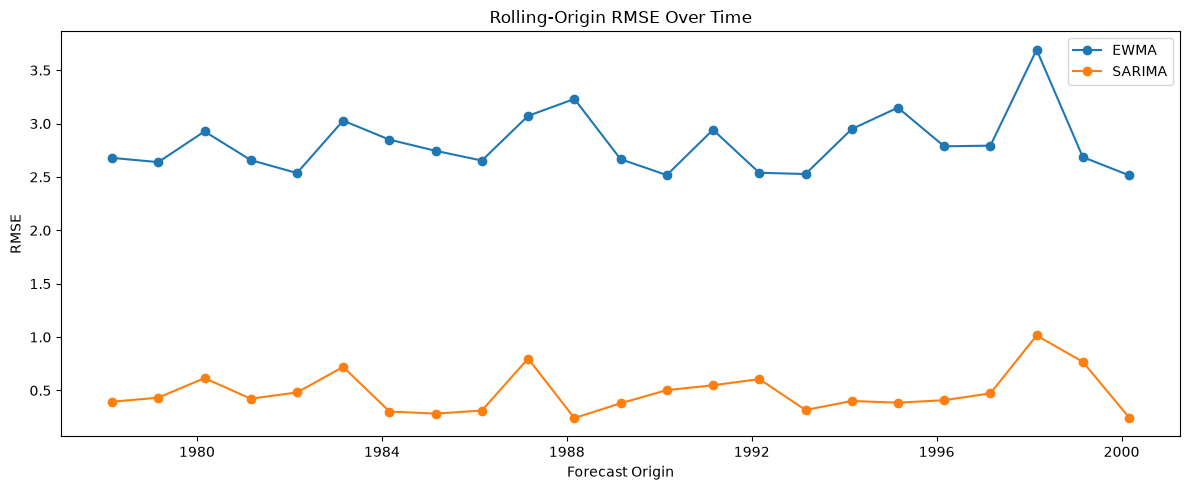

In [25]:
plt.figure(figsize=(12, 5))

for model_name in backtest_results["model"].unique():
    subset = backtest_results[
        backtest_results["model"] == model_name
    ]

    plt.plot(
        subset["origin"],
        subset["RMSE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast Origin")
plt.ylabel("RMSE")
plt.title("Rolling-Origin RMSE Over Time")
plt.legend()

plt.tight_layout()
plt.show()

### Backtesting Stability

Changes in error over time can show whether a model performs consistently or becomes less reliable during certain periods. Increasing errors over time could be a sign of forecast drift or changing patterns in the data.

## SARIMA Residual Diagnostics

Residuals should be reasonably centered around zero without strong remaining patterns.

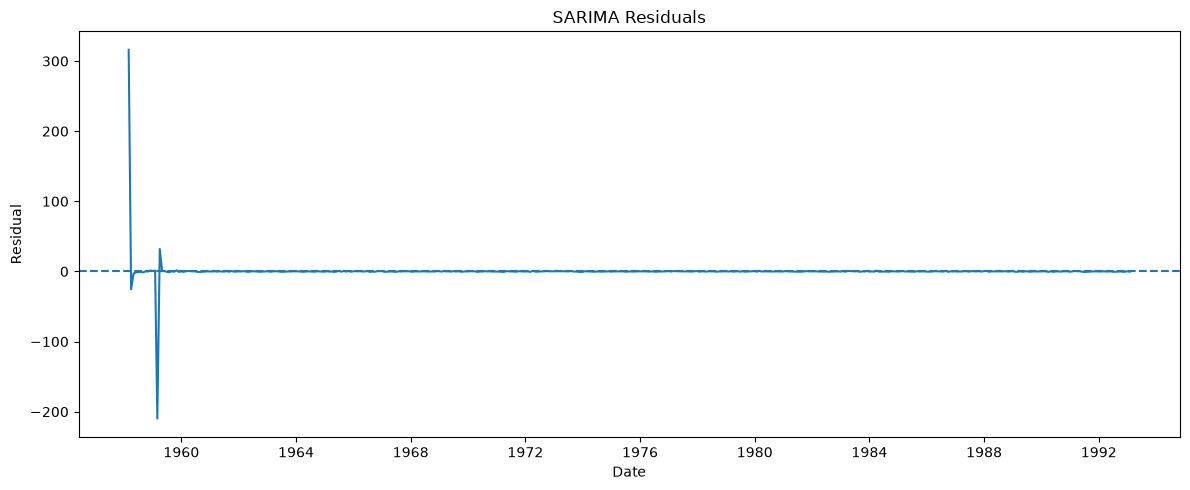

In [26]:
residuals = sarima_fit.resid

plt.figure(figsize=(12, 5))

plt.plot(
    residuals.index,
    residuals
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Date")
plt.ylabel("Residual")
plt.title("SARIMA Residuals")

plt.tight_layout()
plt.show()

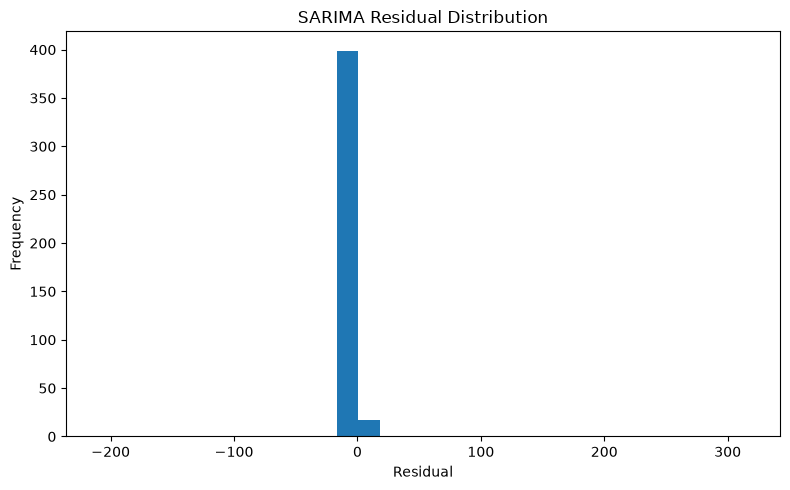

In [27]:
plt.figure(figsize=(8, 5))

plt.hist(
    residuals.dropna(),
    bins=30
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("SARIMA Residual Distribution")

plt.tight_layout()
plt.show()

## Residual Autocorrelation

Autocorrelation can show whether useful time-dependent information remains in the residuals.

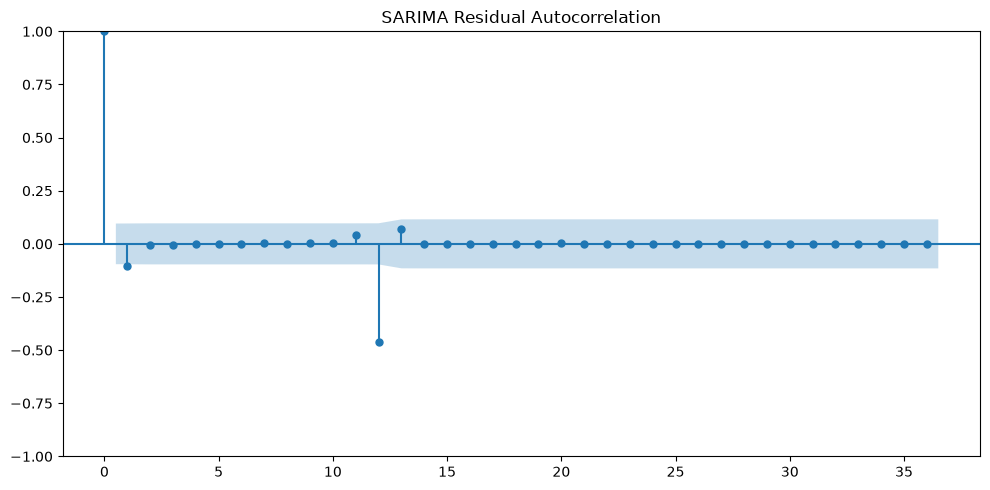

In [28]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(10, 5))

plot_acf(
    residuals.dropna(),
    lags=36,
    ax=plt.gca()
)

plt.title("SARIMA Residual Autocorrelation")
plt.tight_layout()
plt.show()

### Residual Interpretation

Most residual autocorrelations should be close to zero. Strong remaining autocorrelation would suggest that the model has not captured all of the time-dependent structure.

In [29]:
print("Residual mean:", round(residuals.mean(), 3))
print("Residual standard deviation:", round(residuals.std(), 3))
print("Residual observations:", residuals.notna().sum())

Residual mean: 0.273
Residual standard deviation: 18.641
Residual observations: 420


## Reproducibility

I would save the dataset source, monthly resampling method, interpolation method, train/test dates, SARIMA parameters, random seed, software versions, and evaluation results. The time-based split and rolling-origin backtest should also be recorded so the experiment can be repeated later.

## Leakage Prevention

Random train/test splitting was not used. All forecasting evaluations preserve temporal order. The scaler is fit only on the training period, and each backtest model is trained only on observations available before its forecast period.

## Monitoring

I would monitor MAE and RMSE over time along with the distribution of CO2 values and forecast errors. A sustained increase in forecast error would trigger an investigation. I would also monitor missing data, unusual input values, and changes in the seasonal pattern.

## Forecast Drift

Forecast drift could occur if the trend or seasonal pattern changes. I would compare recent forecast errors with historical backtest errors. A sustained increase in MAE or RMSE could indicate that the model needs to be retrained or reviewed.

## Rollback Plan

Each deployed model should have a version, training date, data range, parameters, and evaluation results. If the current model shows a large performance regression, the previous validated model can be restored while the new model is investigated.

## Compute and Latency

EWMA is very cheap to calculate and can be useful as a fallback model. SARIMA requires more computation because the model must estimate time-series parameters. Re-fitting it frequently could increase operational cost, so retraining should be scheduled based on model performance and drift.

## Limitations

This pipeline only uses the CO2 time series itself. It does not include other factors that could affect atmospheric CO2, so external variables could improve future forecasts. The SARIMA parameters were also selected as a reasonable baseline rather than through a large automated search.

## Final Results Summary

The CO2 series shows a strong long-term trend and yearly seasonality. Differencing improved stationarity, while the SARIMA model provided a forecasting approach that accounts for both trend and seasonal behavior. EWMA was used as a simple baseline, and rolling-origin backtesting provided a more realistic comparison than a random split. For production, I would continue monitoring forecast error and data drift and keep a previous validated model available for rollback.

In [30]:
experiment_log = pd.DataFrame({
    "Model": [
        "EWMA",
        "SARIMA"
    ],
    "MAE_Test": [
        ewma_mae,
        sarima_mae
    ],
    "RMSE_Test": [
        ewma_rmse,
        sarima_rmse
    ],
    "Backtest_MAE": [
        backtest_summary.loc["EWMA", "MAE"],
        backtest_summary.loc["SARIMA", "MAE"]
    ],
    "Backtest_RMSE": [
        backtest_summary.loc["EWMA", "RMSE"],
        backtest_summary.loc["SARIMA", "RMSE"]
    ]
})

experiment_log

,Model,MAE_Test,RMSE_Test,Backtest_MAE,Backtest_RMSE
0,EWMA,8.582523,9.788935,2.423635,2.816506
1,SARIMA,1.852472,2.183999,0.410522,0.480410
